In [1]:
import pandas as pd
import os
from sklearn.preprocessing import StandardScaler


In [2]:
print("Current Working Directory:", os.getcwd())


# Load the datasets
mat_data = pd.read_csv('../../student/student-mat.csv', sep=';')
por_data = pd.read_csv('../../student/student-por.csv', sep=';')

# View the first few rows
print(mat_data.head())
print(por_data.head())

Current Working Directory: c:\Users\ivoga\Documents\Git local repositories\projekt-R\testiranje\regresijski_modeli\combined
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4  

In [3]:
print(mat_data.describe())
print(por_data.describe())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

In [4]:
# combine the data
combined_data = pd.concat([mat_data, por_data], ignore_index=True)

In [5]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    combined_data[feature] = label_encoder.fit_transform(combined_data[feature])

# One-hot encoding the categorical features (keep all columns)
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']
combined_data = pd.get_dummies(combined_data, columns=categorical_features)

# Numeric features: No scaling needed for Random Forest
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [7]:
# Definiranje značajki (X) i ciljne varijable (y)
X = combined_data.drop(columns=['G3'])  # G3 je ciljna varijabla
y = combined_data['G3']                # Ciljna varijabla - konačna ocjena

# Podjela podataka na trening i testne skupove
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [8]:
# Inicijalizacija Random Forest modela
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Treniranje modela na trening skupu
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [9]:
# Predviđanje na testnom skupu
y_pred = rf_model.predict(X_test)

# Evaluacija modela
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse}")
print(f"R-squared (R²): {r2}")


Mean Squared Error (MSE): 2.945248983253588
R-squared (R²): 0.8095023856915883


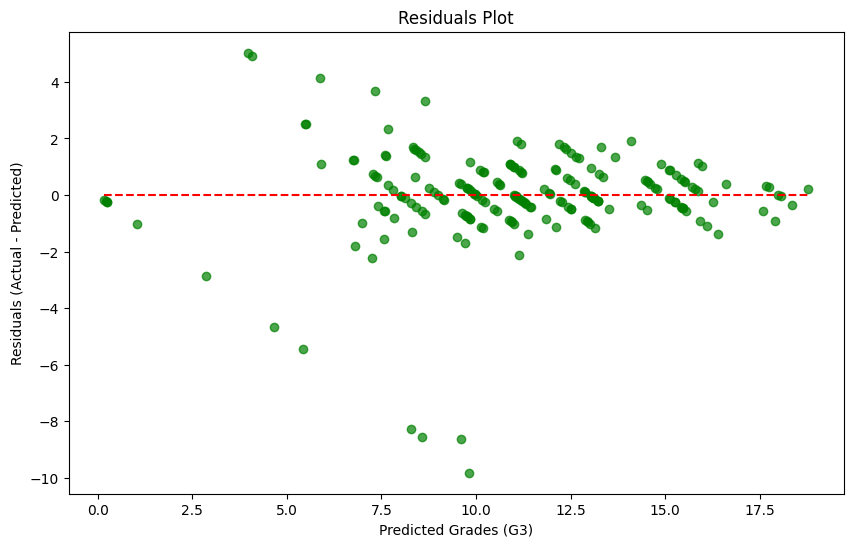

In [10]:
import matplotlib.pyplot as plt

# Residuals
residuals = y_test - y_pred

# Plot Residuals
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7, color='g')
plt.hlines(y=0, xmin=y_pred.min(), xmax=y_pred.max(), color='r', linestyle='--')
plt.xlabel("Predicted Grades (G3)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals Plot")
plt.show()


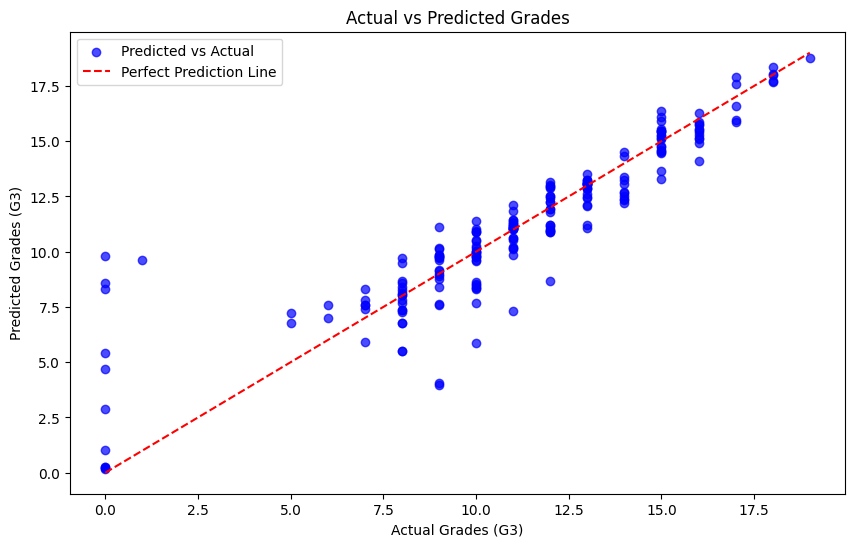

In [11]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='b', label='Predicted vs Actual')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='r', linestyle='--', label='Perfect Prediction Line')
plt.xlabel("Actual Grades (G3)")
plt.ylabel("Predicted Grades (G3)")
plt.title("Actual vs Predicted Grades")
plt.legend()
plt.show()


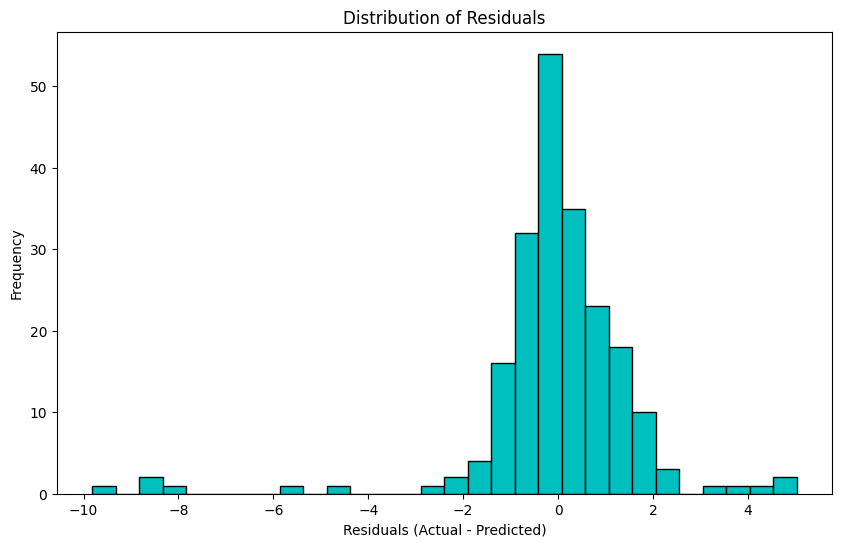

In [12]:
plt.figure(figsize=(10, 6))
plt.hist(residuals, bins=30, color='c', edgecolor='black')
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()


# Optimizacija modela

In [13]:
from sklearn.model_selection import GridSearchCV

# Definiranje parametara za pretragu
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
}

# Grid Search
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=3,  # Križna validacija s 3 podskupa
    scoring='r2',
    verbose=2,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Najbolji parametri
print("Best Parameters:", grid_search.best_params_)

# Treniraj model s najboljim parametrima
best_rf_model = grid_search.best_estimator_


Fitting 3 folds for each of 108 candidates, totalling 324 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}


In [14]:
# Predviđanje pomoću najboljeg modela
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

# Evaluacija
from sklearn.metrics import mean_squared_error, r2_score
mse_best = mean_squared_error(y_test, y_pred_best)
r2_best = r2_score(y_test, y_pred_best)

print(f"Mean Squared Error (MSE): {mse_best}")
print(f"R-squared (R²): {r2_best}")


Mean Squared Error (MSE): 2.7720102651387912
R-squared (R²): 0.8207074018699692


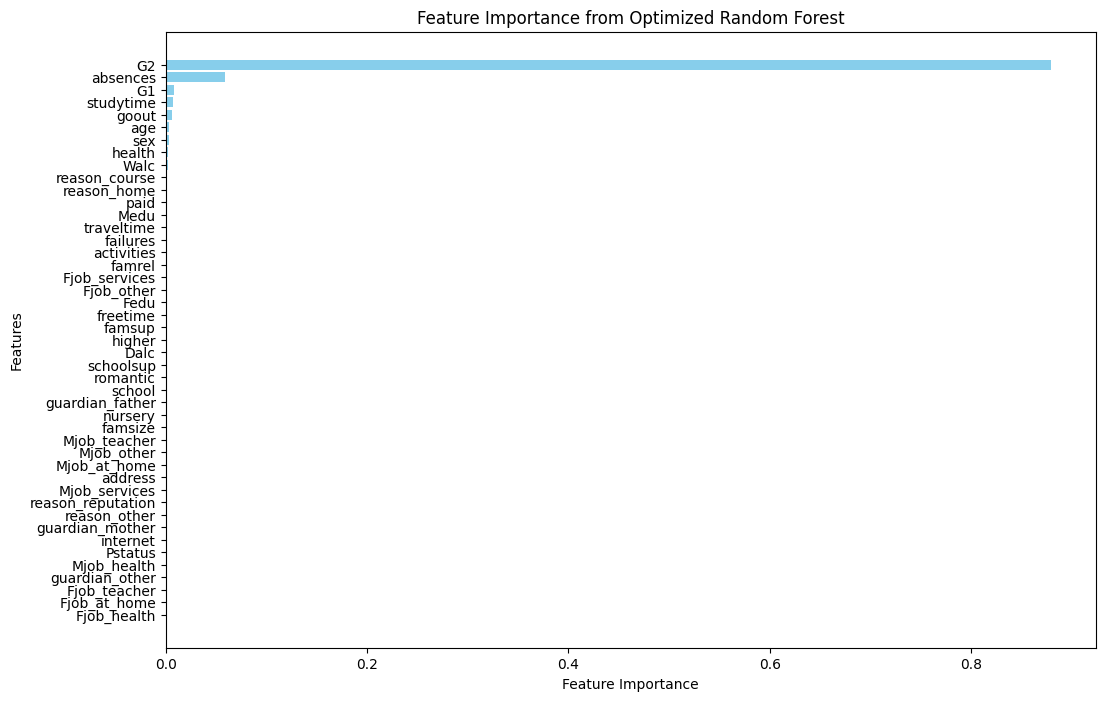

In [15]:
# Važnost značajki
importances = best_model.feature_importances_
sorted_indices = importances.argsort()

plt.figure(figsize=(12, 8))
plt.barh(X_train.columns[sorted_indices], importances[sorted_indices], color='skyblue')
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Feature Importance from Optimized Random Forest")
plt.show()


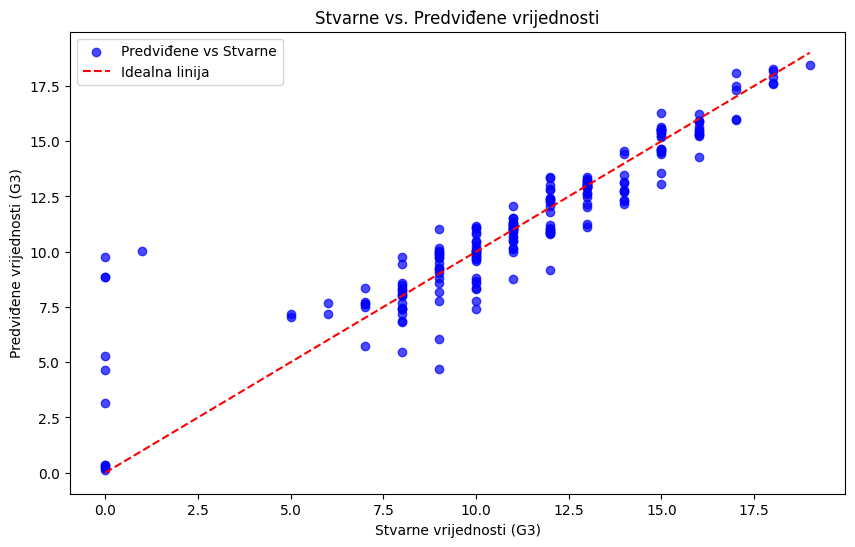

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

# Predikcija na testnom skupu
y_pred = best_rf_model.predict(X_test)

# Stvarne vs. predviđene vrijednosti
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='b', label='Predviđene vs Stvarne')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='r', linestyle='--', label='Idealna linija')
plt.xlabel("Stvarne vrijednosti (G3)")
plt.ylabel("Predviđene vrijednosti (G3)")
plt.title("Stvarne vs. Predviđene vrijednosti")
plt.legend()
plt.show()


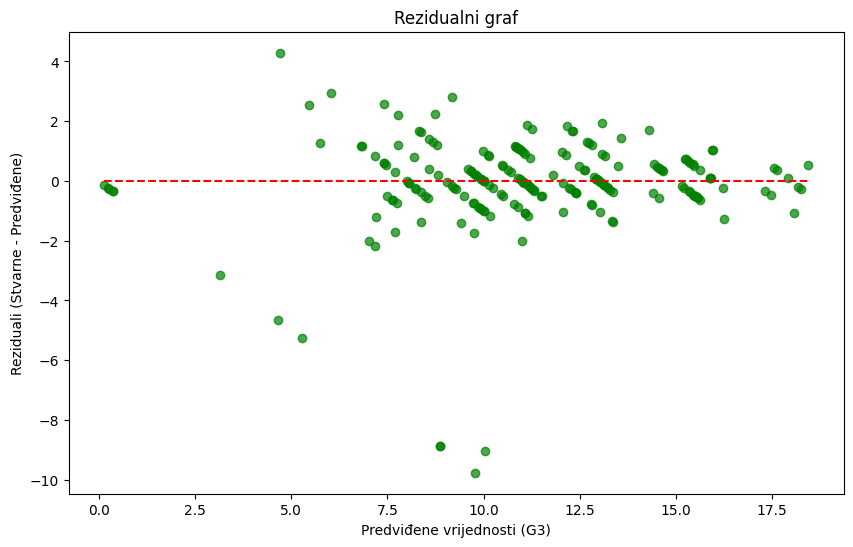

In [17]:
# Rezidualni graf
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7, color='g')
plt.hlines(y=0, xmin=y_pred.min(), xmax=y_pred.max(), color='r', linestyle='--')
plt.xlabel("Predviđene vrijednosti (G3)")
plt.ylabel("Reziduali (Stvarne - Predviđene)")
plt.title("Rezidualni graf")
plt.show()


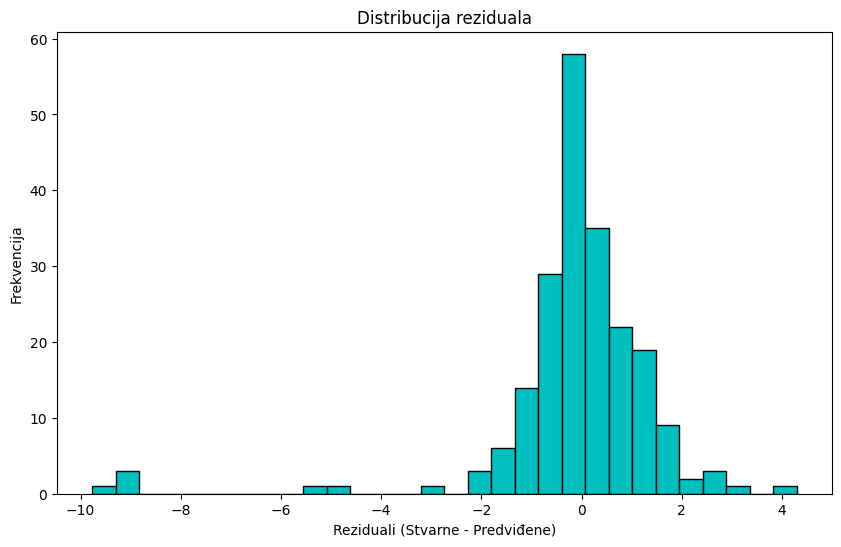

In [18]:
# Distribucija reziduala
plt.figure(figsize=(10, 6))
plt.hist(residuals, bins=30, color='c', edgecolor='black')
plt.xlabel("Reziduali (Stvarne - Predviđene)")
plt.ylabel("Frekvencija")
plt.title("Distribucija reziduala")
plt.show()


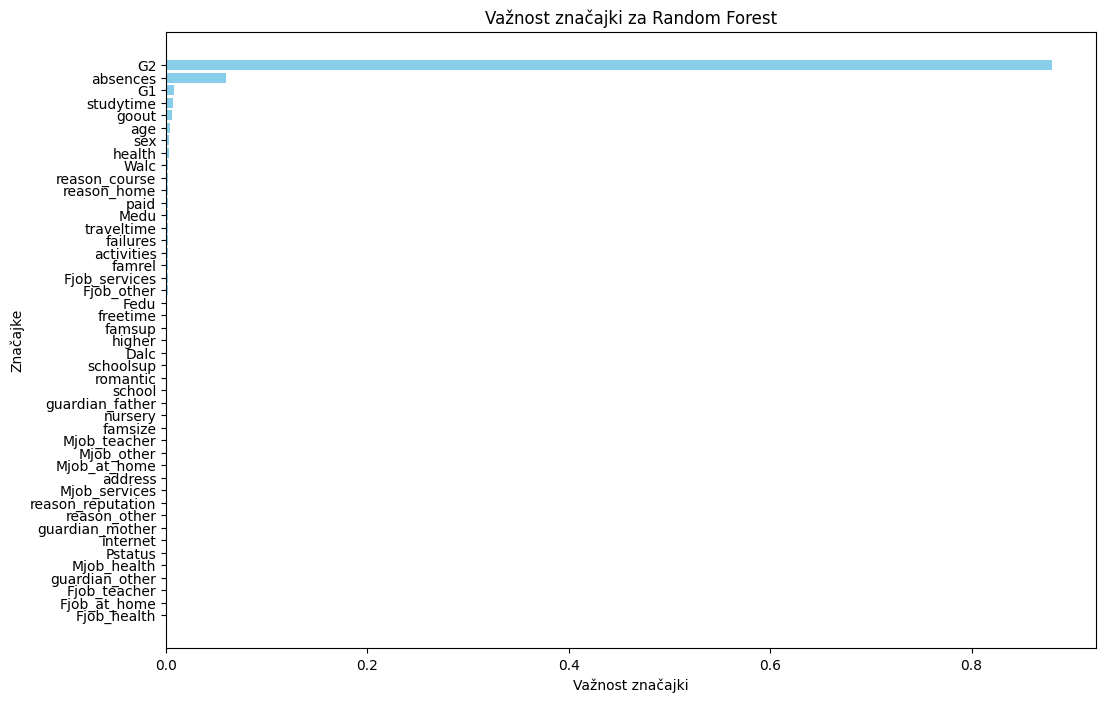

In [19]:
# Važnost značajki
import pandas as pd
import numpy as np

feature_importances = best_rf_model.feature_importances_
features = X_train.columns

# Sortiranje i prikaz značajki
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 8))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='skyblue')
plt.xlabel("Važnost značajki")
plt.ylabel("Značajke")
plt.title("Važnost značajki za Random Forest")
plt.gca().invert_yaxis()
plt.show()
